In [92]:
import numpy as np
import pandas as pd


In [93]:
df = pd.read_csv("spam.csv", encoding="latin-1")
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
3501,ham,I will come to ur home now,NaN,NaN,NaN
4052,ham,I was slept that time.you there?,NaN,NaN,NaN
806,ham,"sure, but make sure he knows we ain't smokin yet",NaN,NaN,NaN
2039,ham,Dont pack what you can buy at any store.like c...,NaN,NaN,NaN
1198,ham,Al he does is moan at me if n e thin goes wron...,NaN,NaN,NaN


In [94]:
# 1.Data cleaning
# 2.EDA
# 3.Text preprocessing
# 4.model building
# 5.evaluation
# 6.improvement
# 7.website
# 8.Deploy


### 1.DATA CLEANING

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [96]:
## drop last 3 col
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)

In [97]:
df.sample(5)

,v1,v2
879,spam,U have a Secret Admirer who is looking 2 make ...
2609,ham,"Awesome, text me when you're restocked"
2120,ham,"Argh my 3g is spotty, anyway the only thing I ..."
726,ham,Of cos can lar i'm not so ba dao ok... 1 pm lo...
2430,ham,How was txting and driving


In [98]:
## renaming the col
df.rename(columns={'v1':'Target','v2':'Text'},inplace=True)
df.sample(5)

,Target,Text
4227,ham,Have you started in skye
2204,ham,Raji..pls do me a favour. Pls convey my Birthd...
4905,ham,Will you come online today night
1470,ham,Take some small dose tablet for fever
262,ham,MY NO. IN LUTON 0125698789 RING ME IF UR AROUN...


In [99]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()

In [100]:
df['Target']=encoder.fit_transform(df['Target'])

In [101]:
df.sample(5)

,Target,Text
792,0,Y?WHERE U AT DOGBREATH? ITS JUST SOUNDING LIKE...
2271,0,Life spend with someone for a lifetime may be ...
4650,1,A å£400 XMAS REWARD IS WAITING FOR YOU! Our co...
1244,0,Now? I'm going out 4 dinner soon..
5077,1,Do you want a New Nokia 3510i colour phone Del...


In [102]:
df.isnull().sum()

Target    0
Text      0
dtype: int64

In [103]:
df.duplicated().sum()

np.int64(403)

In [104]:
df.drop_duplicates(keep='first',inplace=True)
df.duplicated().sum()

np.int64(0)

In [105]:
df.shape

(5169, 2)

### 2.EDA

In [106]:
df['Target'].value_counts()

Target
0    4516
1     653
Name: count, dtype: int64

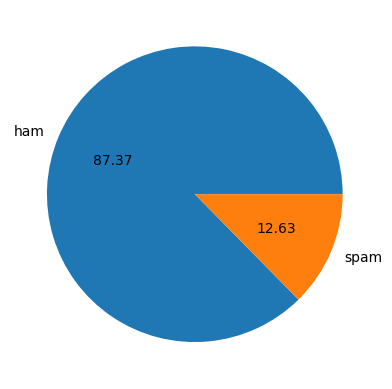

In [107]:
import matplotlib.pyplot as plt
plt.pie(df['Target'].value_counts(),labels=['ham','spam'],autopct="%0.2f")
plt.show()

In [108]:
## data is imbalanced

In [109]:
import nltk

In [110]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [111]:
## number of charater in each text 
df['num_character']=df['Text'].apply(len)

In [112]:
## number of word in each text 
df['num_word']=df['Text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [113]:
df.head()

,Target,Text,num_character,num_word
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [114]:
## number of sentence in each text 
df['num_sentence']=df['Text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [115]:
df.head()

,Target,Text,num_character,num_word,num_sentence
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [116]:
df[['num_character','num_word','num_sentence']].describe()

,num_character,num_word,num_sentence
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.460437,1.965564
std,58.236293,13.334441,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [117]:
## for ham
df[df['Target']==0][['num_character','num_word','num_sentence']].describe()

,num_character,num_word,num_sentence
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.128432,1.820195
std,56.358207,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [118]:
## for spam
df[df['Target']==1][['num_character','num_word','num_sentence']].describe()

,num_character,num_word,num_sentence
count,653.000000,653.000000,653.000000
mean,137.891271,27.672282,2.970904
std,30.137753,7.010932,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


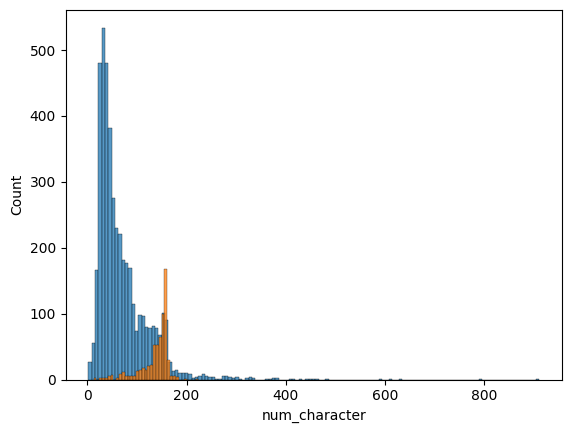

In [119]:
import seaborn as sns
plt.Figure(figsize=(12,8))
sns.histplot(df[df['Target']==0]['num_character'])
sns.histplot(df[df['Target']==1]['num_character'])
plt.show()

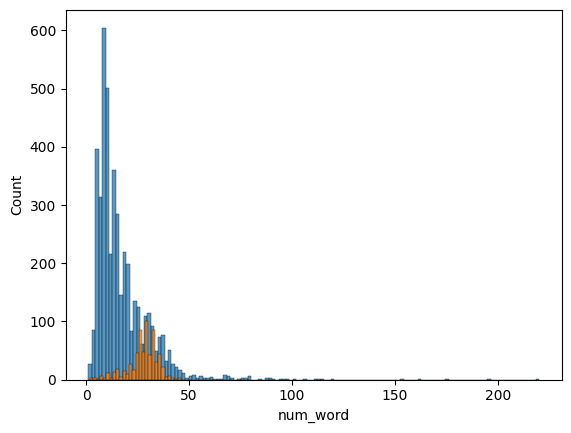

In [120]:
plt.Figure(figsize=(12,8))
sns.histplot(df[df['Target']==0]['num_word'])
sns.histplot(df[df['Target']==1]['num_word'])
plt.show()

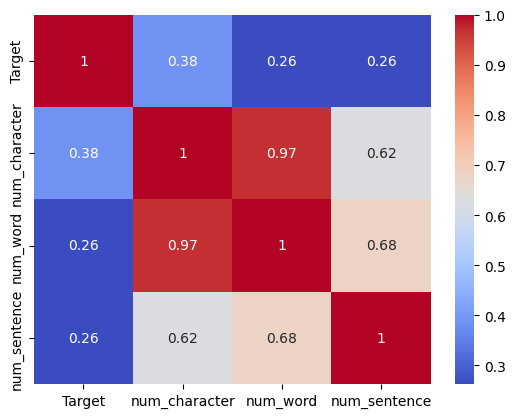

In [121]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

### 3. Data Preprocessing

- Lowercase conversion
- Tokenization
- Removing special characters
- Removing stop words and punctuation
- Stemming

In [122]:
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_word=stopwords.words('english')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [123]:
import string 
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [124]:
from nltk.stem.porter import PorterStemmer 
ps=PorterStemmer()
ps.stem('dancing')

'danc'

In [125]:
def tranform_text(text):
    # Lowercase conversion
    text=text.lower()

    # Tokenization
    text=nltk.word_tokenize(text) # here text words are stored into list 

    # Removing special characters
    y=[]
    for i in text:
        if i.isalnum():
            y.append(i)

    # Removing stop words and punctuation
    text=y[:] # putting everything in text again
    y.clear()

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)


    # Stemming
    text=y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))

    return " ".join(y)

In [126]:
df["transformed_text"]=df["Text"].apply(tranform_text)

In [127]:
df.head()

,Target,Text,num_character,num_word,num_sentence,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [128]:
from wordcloud import WordCloud
wc=WordCloud(width=500,height=500,min_font_size=10,background_color='white')

In [129]:
spam_wc=wc.generate(df[df['Target']==1]['transformed_text'].str.cat(sep=" "))

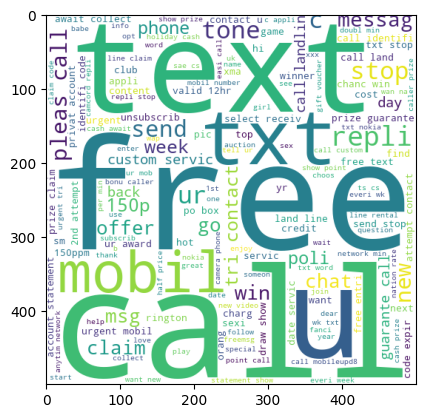

In [130]:
plt.Figure(figsize=(20,10))
plt.imshow(spam_wc)

In [131]:
ham_wc=wc.generate(df[df['Target']==0]['transformed_text'].str.cat(sep=" "))

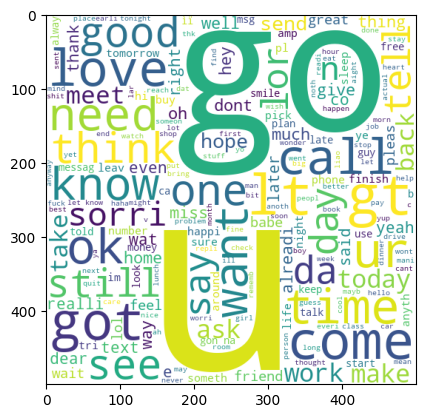

In [132]:
plt.Figure(figsize=(20,10))
plt.imshow(ham_wc)

In [133]:
spam_corpus=[]
for msg in df[df["Target"]==1]["transformed_text"].tolist():
    for word in msg.split():
        spam_corpus.append(word)

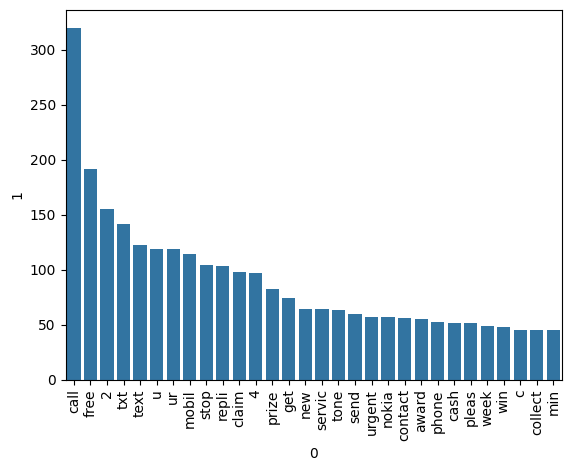

In [134]:
from collections import Counter
temp=pd.DataFrame(Counter(spam_corpus).most_common(30))
sns.barplot(x=temp[0],y=temp[1])
plt.xticks(rotation='vertical')
plt.show()

In [135]:
ham_corpus=[]
for msg in df[df["Target"]==0]["transformed_text"].tolist():
    for word in msg.split():
        ham_corpus.append(word)

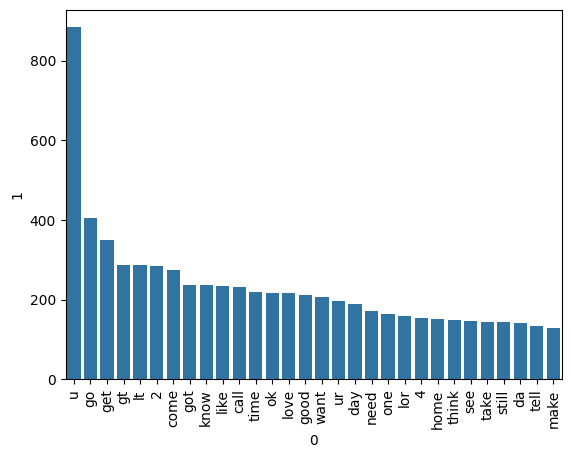

In [136]:
from collections import Counter
temp_ham=pd.DataFrame(Counter(ham_corpus).most_common(30))
sns.barplot(x=temp_ham[0],y=temp_ham[1])
plt.xticks(rotation='vertical')
plt.show()

In [137]:
df.head()

,Target,Text,num_character,num_word,num_sentence,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


### 4.Model Building

In [138]:
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
cv=CountVectorizer() ## bag of word 
tfidf=TfidfVectorizer()

In [139]:
X=tfidf.fit_transform(df['transformed_text']).toarray()

In [140]:
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(5169, 6715))

In [141]:
y=df['Target'].values

In [142]:
from sklearn.model_selection import train_test_split


In [143]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=3)

In [144]:
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score

In [145]:
gnb=GaussianNB()
mnb=MultinomialNB()
bnb=BernoulliNB()

In [146]:
gnb.fit(X_train,y_train)
y_pred1=gnb.predict(X_test)
print(accuracy_score(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred1))
print(precision_score(y_test,y_pred1))


0.8646034816247582
[[773 121]
 [ 19 121]]
0.5


In [147]:
mnb.fit(X_train,y_train)
y_pred2=mnb.predict(X_test)
print(accuracy_score(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))
print(precision_score(y_test,y_pred2))

0.9555125725338491
[[894   0]
 [ 46  94]]
1.0


In [148]:
bnb.fit(X_train,y_train)
y_pred3=bnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))

0.9690522243713733
[[892   2]
 [ 30 110]]
0.9821428571428571


In [149]:
## we choose tf-idf==>>mnb

In [150]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

In [156]:
svc=SVC(kernel='sigmoid',gamma=1.0)
knc=KNeighborsClassifier()
mnb=MultinomialNB()
dtc=DecisionTreeClassifier(max_depth=5)
lrc=LogisticRegression(solver='liblinear',penalty='l1')
rfc=RandomForestClassifier(n_estimators=50,random_state=2)
abc=AdaBoostClassifier(n_estimators=50,random_state=2)
bc=BaggingClassifier(n_estimators=50,random_state=2)
etc=ExtraTreesClassifier(n_estimators=50,random_state=2)
gbdt=GradientBoostingClassifier(n_estimators=50,random_state=2)
xgb=XGBClassifier(n_estimators=50,random_state=2)

In [157]:
clfs={
    'SVC' :svc,
    'KN' :knc,
    'NB' :mnb,
    'DT' :dtc,
    'LR' :lrc,
    'RF':rfc,
    'AdaBoost':abc,
    'Bgc':bc,
    'ETC':etc,
    'GBDT':gbdt,
    'xgb':xgb
}

In [158]:
def train_classifier(clf,X_train,y_train,X_test,y_test):
    clf.fit(X_train,y_train)
    y_pred=clf.predict(X_test)
    accuracy=accuracy_score(y_test,y_pred)
    precision=precision_score(y_test,y_pred)

    return accuracy,precision

In [159]:
accuracy_scores=[]
precision_scores=[]

for name,clf in clfs.items():

    current_accuracy,current_precision=train_classifier(clf,X_train,y_train,X_test,y_test)

    print("For",name)
    print("Accuracy - ",current_accuracy)
    print("Precision - ",current_precision)

    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)


For SVC
Accuracy -  0.9729206963249516
Precision -  1.0
For KN
Accuracy -  0.8945841392649904
Precision -  1.0
For NB
Accuracy -  0.9555125725338491
Precision -  1.0
For DT
Accuracy -  0.9381044487427466
Precision -  0.9042553191489362
For LR
Accuracy -  0.9535783365570599
Precision -  0.9791666666666666


c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


For RF
Accuracy -  0.9680851063829787
Precision -  1.0
For AdaBoost
Accuracy -  0.9206963249516441
Precision -  0.8372093023255814
For Bgc
Accuracy -  0.9661508704061895
Precision -  0.926829268292683
For ETC
Accuracy -  0.9680851063829787
Precision -  1.0
For GBDT
Accuracy -  0.9497098646034816
Precision -  0.9888888888888889
For xgb
Accuracy -  0.9661508704061895
Precision -  0.9906542056074766


In [162]:
performance_df=pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy':accuracy_scores,'precision':precision_scores})
performance_df

,Algorithm,Accuracy,precision
0,SVC,0.972921,1.000000
1,KN,0.894584,1.000000
2,NB,0.955513,1.000000
3,DT,0.938104,0.904255
4,LR,0.953578,0.979167
5,RF,0.968085,1.000000
6,AdaBoost,0.920696,0.837209
7,Bgc,0.966151,0.926829
8,ETC,0.968085,1.000000
9,GBDT,0.949710,0.988889
